# Phase 3: Features + classification (sama, patient 0)

Regions inside sama's predicted liver (watershed, Phase 2): **tumour** = each ground-truth tumour blob; **healthy** = dark spots in the liver that are not tumour (mostly vessels), max 3 per slice.
Features: shape + GLCM (0/45/90/135 degrees) + first-order HU. Classifier: **SVM (RBF kernel)**.

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import skew, kurtosis
from skimage.measure import regionprops, label
from skimage.feature import graycomatrix, graycoprops
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
import joblib

NAME = "sama"
SLICES = f"../data/slices/{NAME}"            # raw CT (HU) + ground-truth masks
ENH = "../phase1/outputs_sama/enhanced"           # Phase 1 output
LIVER = "../phase2/outputs_sama/watershed"        # Phase 2 output (your best method)
OUT = "outputs_sama"
FIGS = "../report/figures/sama"
os.makedirs(OUT, exist_ok=True)

slice_ids = sorted(os.path.basename(f).replace("_enh.png", "") for f in glob.glob(f"{ENH}/*_enh.png"))
print(len(slice_ids), "slices")

def load(sid):
    ct = np.load(f"{SLICES}/{sid}_ct.npy")                              # raw HU (for first-order stats)
    enh = cv2.imread(f"{ENH}/{sid}_enh.png", 0)                         # enhanced 0-255 (for texture)
    liver = cv2.imread(f"{LIVER}/{sid}_liver_pred.png", 0) > 0          # YOUR predicted liver
    tumour = cv2.imread(f"{SLICES}/{sid}_tumour.png", 0) > 0            # ground-truth tumour
    return ct, enh, liver, tumour

16 slices


In [2]:
MIN_AREA = 10          # ignore regions smaller than 10 pixels (too small to measure)
rng = np.random.default_rng(42)

def candidate_spots(enh, liver):
    """Dark spots inside the liver = things that could be tumour (tumours are darker than liver)."""
    inner = cv2.erode(liver.astype(np.uint8), np.ones((9, 9), np.uint8)) > 0   # stay away from the edge
    if not inner.any():
        return np.zeros_like(liver)
    dark = (enh < np.median(enh[inner]) - 25) & inner
    return cv2.morphologyEx(dark.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)) > 0

rois = []    # (slice id, region mask, label)  label: 1 = tumour, 0 = healthy
for sid in slice_ids:
    ct, enh, liver, tumour = load(sid)
    # tumour regions = each separate blob in the ground-truth tumour mask
    for r in regionprops(label(tumour)):
        if r.area >= MIN_AREA:
            m = np.zeros(tumour.shape, bool); m[tuple(r.coords.T)] = True
            rois.append((sid, m, 1))
    # healthy regions = dark spots inside the liver that are NOT tumour (mostly blood vessels)
    healthy = []
    for r in regionprops(label(candidate_spots(enh, liver))):
        m = np.zeros(tumour.shape, bool); m[tuple(r.coords.T)] = True
        if r.area >= MIN_AREA and (m & tumour).sum() == 0:
            healthy.append(m)
    for i in rng.permutation(len(healthy))[:3]:              # max 3 per slice, keeps the classes balanced
        rois.append((sid, healthy[i], 0))

labels = np.array([y for _, _, y in rois])
print(len(rois), "regions:", (labels == 1).sum(), "tumour,", (labels == 0).sum(), "healthy")

70 regions: 24 tumour, 46 healthy


In [3]:
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]           # 0, 45, 90, 135 degrees
ANGLE_NAMES = ["0", "45", "90", "135"]

def shape_features(mask):
    r = regionprops(mask.astype(np.uint8))[0]
    area, perim = r.area, max(r.perimeter, 1e-6)
    return {"area": area,
            "perimeter_area_ratio": perim / area,
            "circularity": 4 * np.pi * area / perim ** 2,      # 1 = perfect circle
            "compactness": perim ** 2 / area,
            "eccentricity": r.eccentricity,                      # 0 = circle, 1 = line
            "solidity": r.solidity}                              # area / convex hull area

def glcm_features(enh, mask, levels=32, per_angle=False):
    """GLCM texture inside the region only (pixels outside the region are ignored)."""
    r = regionprops(mask.astype(np.uint8))[0]
    r0, c0, r1, c1 = r.bbox
    patch = enh[r0:r1, c0:c1].astype(int)
    m = mask[r0:r1, c0:c1]
    q = np.where(m, 1 + patch * (levels - 1) // 255, 0).astype(np.uint8)   # 1..levels inside, 0 outside
    P = graycomatrix(q, distances=[1], angles=ANGLES, levels=levels + 1)
    P = P[1:, 1:, :, :].astype(float)                                      # drop pairs touching "outside"
    P = P / np.maximum(P.sum(axis=(0, 1), keepdims=True), 1e-12)
    feats = {}
    for prop in ["energy", "contrast", "homogeneity", "correlation"]:
        vals = np.nan_to_num(graycoprops(P, prop)[0])                     # one value per angle
        feats.update({f"glcm_{prop}_{a}": v for a, v in zip(ANGLE_NAMES, vals)} if per_angle
                     else {f"glcm_{prop}": vals.mean()})
    ent = [-(P[:, :, 0, k][P[:, :, 0, k] > 0] * np.log2(P[:, :, 0, k][P[:, :, 0, k] > 0])).sum() for k in range(4)]
    feats.update({f"glcm_entropy_{a}": v for a, v in zip(ANGLE_NAMES, ent)} if per_angle
                 else {"glcm_entropy": np.mean(ent)})
    return feats

def first_order_features(ct, mask):
    hu = ct[mask].astype(float)
    return {"mean_HU": hu.mean(), "variance_HU": hu.var(),
            "skewness": skew(hu) if hu.std() > 0 else 0.0,
            "kurtosis": kurtosis(hu) if hu.std() > 0 else 0.0}

# GLCM table at the 4 angles for one tumour (for the report)
sid, m, _ = next(r for r in rois if r[2] == 1)
ct, enh, _, _ = load(sid)
glcm_table = pd.Series(glcm_features(enh, m, per_angle=True))
print(f"GLCM at 4 angles, tumour region in {sid}:")
print(pd.DataFrame({a: glcm_table[[k for k in glcm_table.index if k.endswith("_" + a)]].values
                    for a in ANGLE_NAMES},
                   index=["energy", "contrast", "homogeneity", "correlation", "entropy"]).round(3))
pd.DataFrame({a: glcm_table[[k for k in glcm_table.index if k.endswith("_" + a)]].values for a in ANGLE_NAMES},
             index=["energy", "contrast", "homogeneity", "correlation", "entropy"]).round(3).to_csv(f"{FIGS}/{NAME}_glcm_table.csv")

GLCM at 4 angles, tumour region in p0_s46:
                 0     45     90    135
energy       0.432  0.427  0.403  0.375
contrast     0.368  0.333  0.513  1.135
homogeneity  0.816  0.833  0.744  0.627
correlation  0.918  0.897  0.876  0.762
entropy      2.813  2.830  2.891  3.072


In [4]:
cache = {}
rows = []
for sid, m, y in rois:
    if sid not in cache:
        cache[sid] = load(sid)
    ct, enh, _, _ = cache[sid]
    rows.append({"slice": sid, "label": y,
                 **shape_features(m), **glcm_features(enh, m), **first_order_features(ct, m)})
features = pd.DataFrame(rows)
features.to_csv(f"{OUT}/phase3_features.csv", index=False)
print(features.groupby("label").mean(numeric_only=True).T.round(3).rename(columns={0: "healthy", 1: "tumour"}))

label                 healthy   tumour
area                  177.957  107.208
perimeter_area_ratio    0.483    0.488
circularity             0.707    0.887
compactness            24.193   14.964
eccentricity            0.809    0.680
solidity                0.832    0.896
glcm_energy             0.532    0.450
glcm_contrast           0.498    0.423
glcm_homogeneity        0.814    0.794
glcm_correlation        0.622    0.736
glcm_entropy            2.306    2.684
mean_HU                88.246   91.225
variance_HU           303.010  212.180
skewness               -0.131    0.022
kurtosis               -0.190   -0.063


In [5]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
import joblib

X = features.drop(columns=["slice", "label"]).values
y = features["label"].values

# ---- groups: every region from the same slice stays on the same side of the split ----
# Neighbouring slices show the same tumour, so a random split of regions would put near-copies in train AND test.
# Consecutive slices are joined into blocks of 3 (or 2) only if that still leaves >= 5 training groups for 5-fold CV.
slice_no = features["slice"].str.extract(r"_s(\d+)")[0].astype(int)
position = slice_no.map({s: i for i, s in enumerate(sorted(slice_no.unique()))}).values   # 0, 1, 2, ... along the scan
def grouped_split(groups):
    """70/30 split by group. Groups differ in size, so try 50 seeds and keep the one whose test part is closest
    to 30% of the REGIONS (only sizes are looked at, never the scores). Needs >= 5 train groups + both classes in test."""
    best_split, best_gap = None, 1.0
    for seed in range(50):
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed).split(X, y, groups))
        if len(np.unique(groups[tr])) >= 5 and len(np.unique(y[te])) == 2 and abs(len(te) / len(y) - 0.3) < best_gap:
            best_split, best_gap = (tr, te), abs(len(te) / len(y) - 0.3)
    return best_split

for BLOCK in (3, 2, 1):
    groups = position // BLOCK
    split = grouped_split(groups)
    if split is not None:
        break
idx_train, idx_test = split
X_train, X_test, y_train, y_test = X[idx_train], X[idx_test], y[idx_train], y[idx_test]
print(f"block = {BLOCK} slice(s) per group | train: {len(np.unique(groups[idx_train]))} groups, {len(idx_train)} regions"
      f" | test: {len(np.unique(groups[idx_test]))} groups, {len(idx_test)} regions"
      f" ({len(idx_test) / len(y):.0%} of all regions)")

from sklearn.svm import SVC
# SVM: draws the widest possible boundary between the tumour and healthy points
# 5-fold grouped cross-validation on the 70% TRAIN part only picks the C; the 30% test part stays untouched
cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma="scale")),
                      {"svc__C": [0.1, 1, 10, 100]}, cv=cv5, scoring="f1")
search.fit(X_train, y_train, groups=groups[idx_train])
best = search.best_params_["svc__C"]
model = search.best_estimator_                     # already refitted on the whole 70% train part
y_pred = model.predict(X_test)

cv = cross_validate(model, X_train, y_train, groups=groups[idx_train], cv=cv5, scoring=["accuracy", "f1"])
print(f"tuned C = {best}  (tried [0.1, 1, 10, 100])")
print(f"5-fold grouped CV on train: accuracy {cv['test_accuracy'].mean():.3f} +/- {cv['test_accuracy'].std():.3f}"
      f"  folds: {np.round(cv['test_accuracy'], 3)}")
print(f"                            F1       {cv['test_f1'].mean():.3f} +/- {cv['test_f1'].std():.3f}"
      f"  folds: {np.round(cv['test_f1'], 3)}")
cv_summary = {"tuned C": best, "group block (slices)": BLOCK,
              "CV accuracy mean": cv["test_accuracy"].mean(), "CV accuracy std": cv["test_accuracy"].std(),
              "CV F1 mean": cv["test_f1"].mean(), "CV F1 std": cv["test_f1"].std()}

block = 2 slice(s) per group | train: 5 groups, 48 regions | test: 3 groups, 22 regions (31% of all regions)


tuned C = 100  (tried [0.1, 1, 10, 100])
5-fold grouped CV on train: accuracy 0.783 +/- 0.127  folds: [0.875 0.556 0.818 0.917 0.75 ]
                            F1       0.668 +/- 0.216  folds: [0.8   0.333 0.8   0.909 0.5  ]


Test set: 22 regions (6 tumour, 16 healthy)
  accuracy               0.955
  sensitivity (recall)   0.833
  specificity            1.000
  F1                     0.909


95% bootstrap CI (test groups resampled):
  accuracy               [0.875, 1.000]
  sensitivity (recall)   [0.500, 1.000]
  specificity            [1.000, 1.000]
  F1                     [0.667, 1.000]


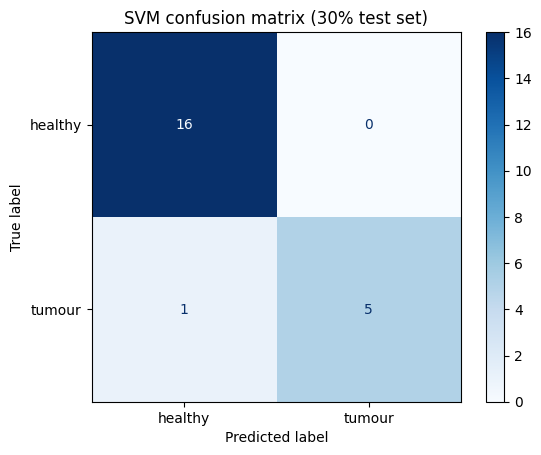

In [6]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
metrics = {"accuracy": accuracy_score(y_test, y_pred),
           "sensitivity (recall)": tp / (tp + fn) if tp + fn else 0,   # tumours correctly found
           "specificity": tn / (tn + fp) if tn + fp else 0,            # healthy correctly cleared
           "F1": f1_score(y_test, y_pred, zero_division=0)}
print(f"Test set: {len(y_test)} regions ({(y_test == 1).sum()} tumour, {(y_test == 0).sum()} healthy)")
for k, v in metrics.items():
    print(f"  {k:22s} {v:.3f}")
# ---- 95% confidence intervals: bootstrap over the test GROUPS (slices), 2000 resamples ----
def scores(t, p):
    tn, fp, fn, tp = confusion_matrix(t, p, labels=[0, 1]).ravel()
    return [accuracy_score(t, p), tp / (tp + fn) if tp + fn else np.nan, tn / (tn + fp) if tn + fp else np.nan,
            f1_score(t, p, zero_division=0)]
boot_rng = np.random.default_rng(0)
test_groups = groups[idx_test]
boot = []
for _ in range(2000):
    pick = np.concatenate([np.where(test_groups == g)[0] for g in boot_rng.choice(np.unique(test_groups), len(np.unique(test_groups)))])
    boot.append(scores(y_test[pick], y_pred[pick]))
lo, hi = np.nanpercentile(boot, 2.5, axis=0), np.nanpercentile(boot, 97.5, axis=0)
ci = {}
print("95% bootstrap CI (test groups resampled):")
for k, a, b in zip(metrics, lo, hi):
    ci[f"{k} CI low"], ci[f"{k} CI high"] = a, b
    print(f"  {k:22s} [{a:.3f}, {b:.3f}]")
pd.DataFrame([{**metrics, **cv_summary, **ci}]).to_csv(f"{OUT}/phase3_metrics.csv", index=False)

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=[0, 1]),
                       display_labels=["healthy", "tumour"]).plot(cmap="Blues")
plt.title("SVM confusion matrix (30% test set)")
plt.savefig(f"{FIGS}/{NAME}_p3_confusion_matrix.png", dpi=120, bbox_inches="tight"); plt.show()

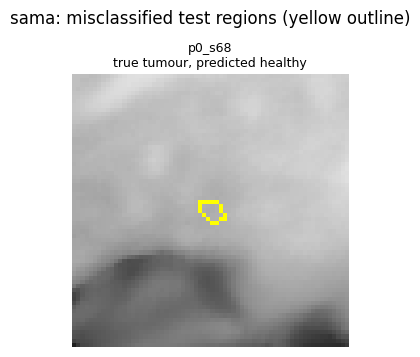

# Phase 3 failed cases: sama

Test set: 22 regions, **1 misclassified**.

| Slice | True | Predicted | Area (px) | Mean HU | Likely reason |
|---|---|---|---|---|---|
| p0_s68 | tumour | healthy | 30 | 100 | tumour region too small to measure shape/texture reliably |


In [7]:
# ---- failed cases: the test regions the classifier got wrong ----
FAILED = f"../report/failed_cases/{NAME}"
os.makedirs(FAILED, exist_ok=True)
wrong = idx_test[y_pred != y_test]
names = {0: "healthy", 1: "tumour"}
lines = [f"# Phase 3 failed cases: {NAME}", "",
         f"Test set: {len(y_test)} regions, **{len(wrong)} misclassified**.", "",
         "| Slice | True | Predicted | Area (px) | Mean HU | Likely reason |", "|---|---|---|---|---|---|"]
for i in wrong:
    sid, m, true = rois[i]
    row = features.iloc[i]
    if true == 1 and row["area"] < 100:
        why = "tumour region too small to measure shape/texture reliably"
    elif true == 1:
        why = "tumour looks like normal liver (similar brightness/texture)"
    else:
        why = "healthy dark structure (vessel or organ edge) that looks tumour-like"
    lines.append(f"| {sid} | {names[true]} | {names[1 - true]} | {int(row['area'])} | {row['mean_HU']:.0f} | {why} |")
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(3.4 * len(wrong), 3.6), squeeze=False)
    for a, i in zip(axes[0], wrong):
        sid, m, true = rois[i]
        rgb = cv2.cvtColor(load(sid)[1], cv2.COLOR_GRAY2RGB)
        contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, contours, -1, (255, 255, 0), 1)
        ys, xs = np.where(m)
        y0, y1, x0, x1 = max(ys.min() - 30, 0), ys.max() + 30, max(xs.min() - 30, 0), xs.max() + 30
        a.imshow(rgb[y0:y1, x0:x1]); a.axis("off")
        a.set_title(f"{sid}\ntrue {names[true]}, predicted {names[1 - true]}", fontsize=9)
    plt.suptitle(f"{NAME}: misclassified test regions (yellow outline)")
    plt.tight_layout(); plt.savefig(f"{FAILED}/{NAME}_p3_misclassified.png", dpi=120, bbox_inches="tight"); plt.show()
else:
    lines.append("| - | - | - | - | - | no mistakes in this test split |")
open(f"{FAILED}/{NAME}_phase3_failed_cases.md", "w").write("\n".join(lines))
print("\n".join(lines))

In [8]:
model.fit(X, y)                                  # final model trained on all regions
joblib.dump({"model": model, "feature_names": list(features.columns[2:])}, f"{OUT}/svm_model.joblib")
print("saved model to", f"{OUT}/svm_model.joblib")

saved model to outputs_sama/svm_model.joblib
